Name Muhtasim Haque Nahian

Labpartner(s) Taherunnesa Rahi

In [12]:
#import statements go here
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.ticker import MultipleLocator, PercentFormatter, MaxNLocator

# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

In [3]:
# Load data

players = pd.read_csv("player_stats.csv")
display(players.head())

,player_id,player_name,team_id,position,matches_played,matches_started,minutes_played,goals,assists,shots,...,yellow_cards,red_cards,penalty_goals,own_goals,clean_sheets,saves,goals_conceded,average_rating,data_source,last_verified
0,1,José Raúl Rangel,1,GK,5,5,438,0,0,NaN,...,0,0,0,0,4.0,7.0,3.0,NaN,sofascore.com,2026-07-19
1,2,Jorge Eduardo Sanchez,1,DEF,5,5,439,0,1,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
2,3,César Jasib Montes,1,DEF,3,2,165,0,0,NaN,...,0,1,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
3,4,Edson Omar Alvarez,1,DEF,2,0,75,0,0,NaN,...,1,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19
4,5,Johan Felipe Vasquez,1,DEF,2,2,180,0,0,NaN,...,0,0,0,0,NaN,NaN,NaN,NaN,sofascore.com,2026-07-19


### Comparison of Total and Per-90 Goal Contributions

I compared midfielders and forwards who played at least **450 minutes**, selecting the top 12 by goal contributions per 90 minutes. Goal contributions include both goals and assists:

$$
\text{Goal contributions} = \text{Goals} + \text{Assists}
$$

$$
\text{Goal contributions per 90}
= \frac{\text{Goals} + \text{Assists}}{\text{Minutes played}}\times90
$$

Then, I filtered eligible players, calculated these statistics, and ranked them by their per-90 contributions. In the stacked bar charts, the left panel shows total contributions, while the right panel shows contributions adjusted for playing time. Green represents goals, and blue represents assists.

The dashed line represents the **minutes-weighted benchmark** across all eligible players, calculated as:

$$
\text{Benchmark}
= \frac{\sum_i(\text{Goals}_i+\text{Assists}_i)}
{\sum_i\text{Minutes played}_i}\times90
$$

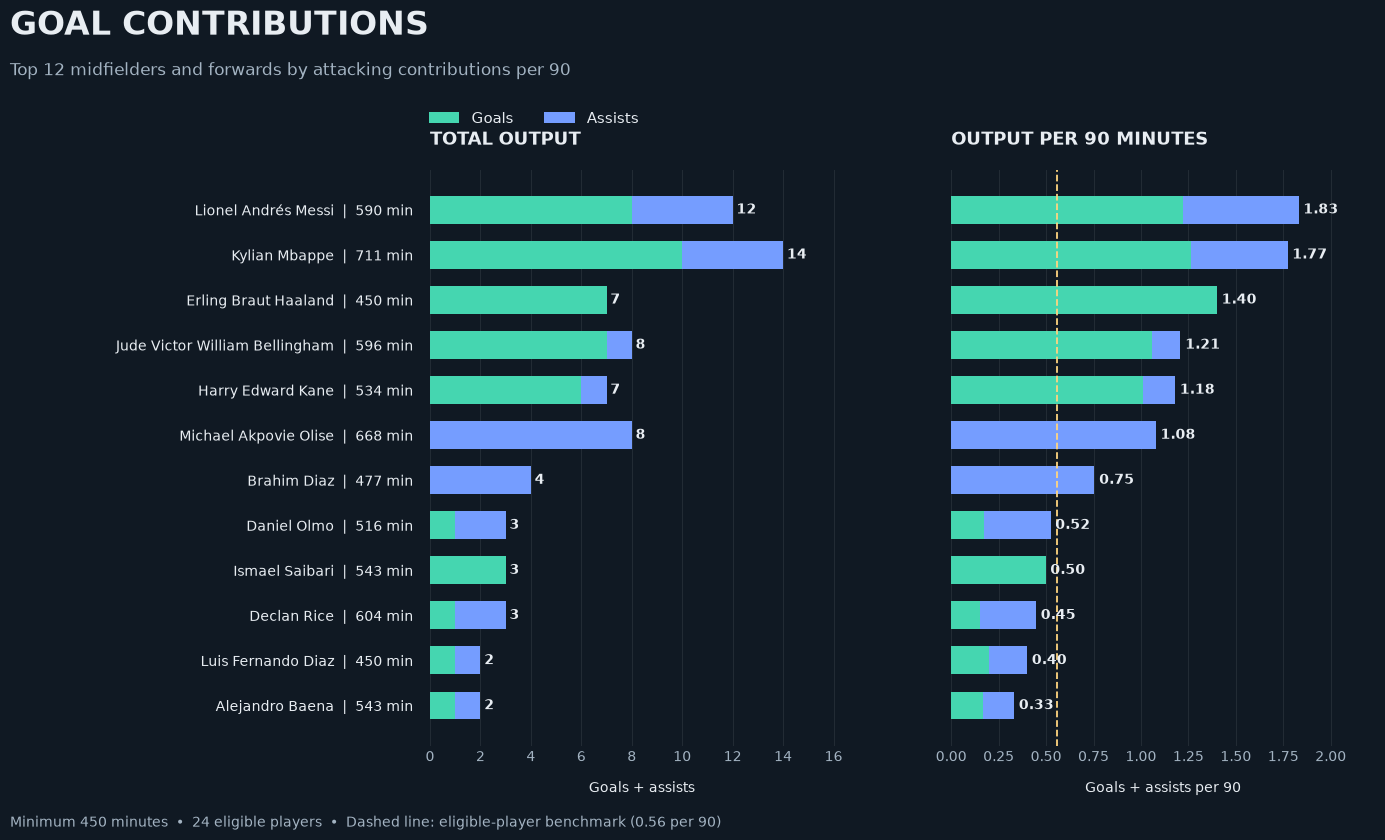

In [5]:
# Select attacking players with substantial playing time
attackers = players.loc[players["position"].isin(["FWD", "MID"]) &
    (players["minutes_played"] >= 450)].dropna(subset=["goals", "assists", "minutes_played"]).copy()

# Calculate total output and output per 90 minutes
attackers["goal_contributions"] = attackers["goals"] + attackers["assists"]
attackers["goals_per90"] = attackers["goals"] / attackers["minutes_played"] * 90
attackers["assists_per90"] = attackers["assists"] / attackers["minutes_played"] * 90
attackers["contributions_per90"] = (attackers["goals_per90"] + attackers["assists_per90"])

# Select the top 12 by rate, using total output to break ties
top12 = (attackers.sort_values(["contributions_per90", "goal_contributions"], ascending=[False, False]).head(12).sort_values("contributions_per90"))

# Minutes-weighted benchmark across ALL eligible attackers
benchmark = (attackers["goal_contributions"].sum() / attackers["minutes_played"].sum() * 90)

# Design
background = "#101923"
foreground = "#E8EDF2"
muted = "#A3B3C2"
goal_color = "#45D6B0"
assist_color = "#759DFF"

y = np.arange(len(top12))

with plt.rc_context({"font.family": "DejaVu Sans", "text.color": foreground, "axes.labelcolor": foreground,
    "xtick.color": muted, "ytick.color": foreground}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 9), sharey=True, facecolor=background)

    fig.subplots_adjust(left=0.32, right=0.95, top=0.80, bottom=0.16, wspace=0.23)

    for ax in (ax1, ax2):
        ax.set_facecolor(background)
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="white", alpha=0.08)
        ax.tick_params(axis="both", length=0)

        for spine in ax.spines.values():
            spine.set_visible(False)

    # Panel 1: Total contributions
    ax1.barh(y, top12["goals"], color=goal_color, height=0.62, label="Goals")
    ax1.barh(y, top12["assists"], left=top12["goals"], color=assist_color, height=0.62, label="Assists")

    # Panel 2: Contributions per 90
    ax2.barh(y, top12["goals_per90"], color=goal_color, height=0.62)
    ax2.barh(y, top12["assists_per90"], left=top12["goals_per90"], color=assist_color, height=0.62)

    # Same player order in both panels
    labels = [f"{row.player_name}  |  {int(row.minutes_played)} min"
        for row in top12.itertuples()
    ]
    ax1.set_yticks(y)
    ax1.set_yticklabels(labels, fontsize=10)
    ax1.tick_params(axis="y", pad=12)

    # End labels
    for i, row in enumerate(top12.itertuples()):
        ax1.text(row.goal_contributions + 0.15, i, f"{int(row.goal_contributions)}", va="center", fontsize=10, fontweight="bold")
        ax2.text(row.contributions_per90 + 0.025, i, f"{row.contributions_per90:.2f}", va="center", fontsize=10, fontweight="bold")

    # Benchmark applies to all eligible attackers, not only the top 12
    ax2.axvline(benchmark, color="#FFD580", linestyle="--", linewidth=1.3)

    ax1.set_xlim(0, top12["goal_contributions"].max() * 1.20)
    ax2.set_xlim(0, top12["contributions_per90"].max() * 1.22)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax1.set_title("TOTAL OUTPUT", loc="left", color=foreground, fontsize=13, fontweight="bold", pad=18)
    ax2.set_title("OUTPUT PER 90 MINUTES", loc="left", color=foreground, fontsize=13, fontweight="bold", pad=18)

    ax1.set_xlabel("Goals + assists", labelpad=12)
    ax2.set_xlabel("Goals + assists per 90", labelpad=12)

    handles, legend_labels = ax1.get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="upper left", bbox_to_anchor=(0.31, 0.88),
        frameon=False, ncol=2, fontsize=11, labelcolor=foreground)

    fig.text(0.04, 0.95, "GOAL CONTRIBUTIONS", fontsize=24, fontweight="bold")
    fig.text(0.04, 0.905, "Top 12 midfielders and forwards by attacking contributions per 90", fontsize=12, color=muted)
    fig.text(0.04, 0.07,
        f"Minimum 450 minutes  •  {len(attackers)} eligible players  •  "
        f"Dashed line: eligible-player benchmark ({benchmark:.2f} per 90)",
        fontsize=10, color=muted)
    plt.show()

This comparison distinguishes accumulated output from the rate of contribution. For example, Mbappe recorded more total contributions than Messi (14 versus 12), but Messi had a higher contribution rate (1.83 versus 1.77 per 90 minutes).

### Goalkeeper Performance: Workload and Save Percentage

I compared goalkeepers who played at least **270 minutes** to examine how their save percentage varied with workload. I selected eligible goalkeepers with the required statistics and a positive number of estimated shots faced, leaving 42 players.

I estimated shots on target faced by adding saves and goals conceded:

$$
\text{Estimated shots faced} = \text{Saves} + \text{Goals conceded}
$$

I then calculated workload per 90 minutes and save percentage:

$$
\text{Shots faced per 90}
= \frac{\text{Estimated shots faced}}{\text{Minutes played}}\times90
$$

$$
\text{Save percentage}
= \frac{\text{Saves}}{\text{Estimated shots faced}}\times100
$$

Then, I created a bubble scatter plot with workload on the x-axis and save percentage on the y-axis. Bubble area represents minutes played, while color represents save percentage. I highlighted the four goalkeepers with the highest save percentages and the four with the highest workloads.

The dashed lines represent pooled benchmarks across all eligible goalkeepers:

$$
\text{Workload benchmark}
= \frac{\sum_i\text{Estimated shots faced}_i}
{\sum_i\text{Minutes played}_i}\times90
= 4.39
$$

$$
\text{Save percentage benchmark}
= \frac{\sum_i\text{Saves}_i}
{\sum_i\text{Estimated shots faced}_i}\times100
= 71.6\%
$$

Goalkeepers in the upper-right region faced an above-average workload while maintaining an above-average save percentage.

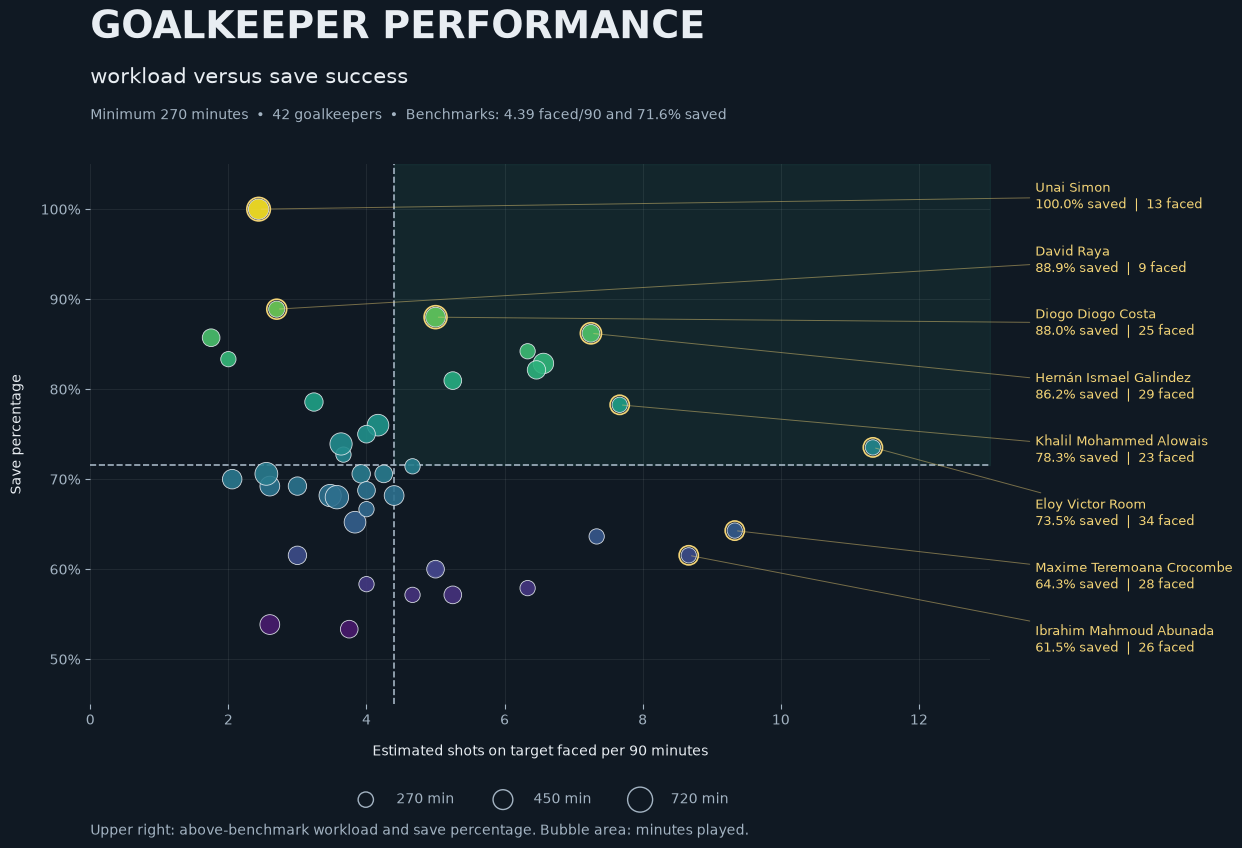

In [7]:
# Select goalkeepers with sufficient playing time
gk = players.loc[(players["position"] == "GK") & (players["minutes_played"] >= 270)
    ].dropna(subset=["saves", "goals_conceded", "minutes_played"]).copy()

# Estimate shots on target faced
gk["shots_faced"] = gk["saves"] + gk["goals_conceded"]
gk = gk[gk["shots_faced"] > 0].copy()

# Separate workload from save success
gk["shots_faced_per90"] = (gk["shots_faced"] / gk["minutes_played"] * 90)
gk["save_percentage"] = gk["saves"] / gk["shots_faced"] * 100

# Pooled benchmarks across eligible goalkeepers
workload_benchmark = (gk["shots_faced"].sum() / gk["minutes_played"].sum() * 90)
save_benchmark = gk["saves"].sum() / gk["shots_faced"].sum() * 100

# Label the four highest save percentages and four heaviest workloads
highlight = (gk.nlargest(4, "save_percentage").combine_first(gk.nlargest(4, "shots_faced_per90")).sort_values("save_percentage", ascending=False))

background = "#101923"
foreground = "#E8EDF2"
muted = "#A3B3C2"
accent = "#F3D477"

with plt.rc_context({"font.family": "DejaVu Sans", "text.color": foreground, "axes.labelcolor": foreground,
    "xtick.color": muted, "ytick.color": muted}):
    fig, ax = plt.subplots(figsize=(15, 9), facecolor=background)
    ax.set_facecolor(background)
    fig.subplots_adjust(left=0.09, right=0.69, top=0.80, bottom=0.20)

    xmax = gk["shots_faced_per90"].max() * 1.15
    ymin = max(0, np.floor(gk["save_percentage"].min() / 10) * 10 - 5)

    # Highlight the high-workload, high-save-percentage area
    ax.fill_between([workload_benchmark, xmax], save_benchmark, 105, color="#45D6B0", alpha=0.07)

    ax.axvline(workload_benchmark, color=muted, linestyle="--", linewidth=1.2)
    ax.axhline(save_benchmark, color=muted, linestyle="--", linewidth=1.2)

    # Bubble area represents playing time
    points = ax.scatter(gk["shots_faced_per90"], gk["save_percentage"], s=gk["minutes_played"] * 0.45, c=gk["save_percentage"],
        cmap="viridis", vmin=50, vmax=100, edgecolors=foreground, linewidths=0.6, alpha=0.9, zorder=3)

    ax.scatter(highlight["shots_faced_per90"], highlight["save_percentage"], s=highlight["minutes_played"] * 0.45 + 70, facecolors="none",
        edgecolors=accent, linewidths=1.2, zorder=4)

    # Place selected player labels outside the plotting area
    label_positions = np.linspace(0.94, 0.12, len(highlight))

    for (_, row), label_y in zip(highlight.iterrows(), label_positions):
        label = (
            f"{row['player_name']}\n"
            f"{row['save_percentage']:.1f}% saved"
            f"  |  {int(row['shots_faced'])} faced"
        )

        ax.annotate(label, xy=(row["shots_faced_per90"], row["save_percentage"]), xycoords="data", xytext=(1.05, label_y),
            textcoords="axes fraction", color=accent, fontsize=9, va="center", annotation_clip=False,
            arrowprops={"arrowstyle": "-", "color": accent, "linewidth": 0.7, "alpha": 0.45})

    ax.set_xlim(0, xmax)
    ax.set_ylim(ymin, 105)
    ax.set_yticks(np.arange(np.ceil(ymin / 10) * 10, 101, 10))
    ax.yaxis.set_major_formatter(PercentFormatter(100))

    ax.set_xlabel("Estimated shots on target faced per 90 minutes", labelpad=12)
    ax.set_ylabel("Save percentage", labelpad=12)
    ax.grid(color="white", alpha=0.07)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    # Bubble-size legend
    size_handles = [
        ax.scatter([], [], s=minutes * 0.45, facecolors="none", edgecolors=muted, label=f"{minutes} min")
        for minutes in [270, 450, 720]
    ]

    ax.legend(handles=size_handles, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False, labelcolor=muted,
        handletextpad=1.2, columnspacing=2.5)

    fig.text(0.09, 0.94, "GOALKEEPER PERFORMANCE", fontsize=27, fontweight="bold")
    fig.text(0.09, 0.89, "workload versus save success", fontsize=15)
    fig.text(0.09, 0.85,
        f"Minimum 270 minutes  •  {len(gk)} goalkeepers  •  "
        f"Benchmarks: {workload_benchmark:.2f} faced/90 and "
        f"{save_benchmark:.1f}% saved", fontsize=10, color=muted
)
    fig.text(
        0.09, 0.055,
        "Upper right: above-benchmark workload and save percentage. "
        "Bubble area: minutes played.",
        fontsize=10, color=muted
    )

    plt.show()

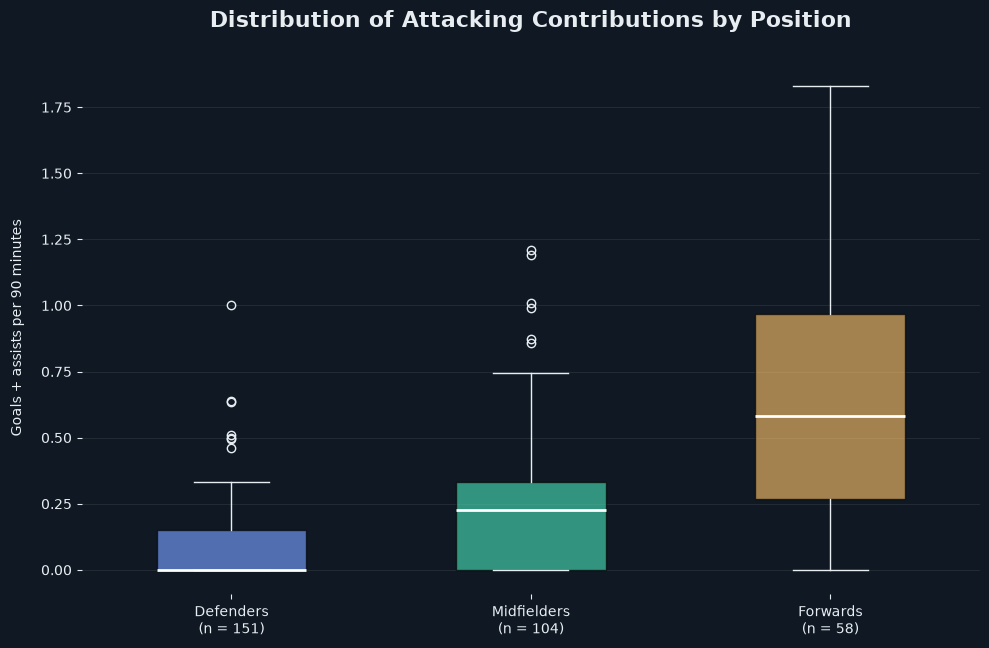

In [10]:
# Select outfield players with at least 270 minutes
box_data = players.loc[players["position"].isin(["DEF", "MID", "FWD"]) & (players["minutes_played"] >= 270)
].dropna(subset=["goals", "assists", "minutes_played"]).copy()

box_data["contributions_per90"] = ((box_data["goals"] + box_data["assists"]) / box_data["minutes_played"] * 90)

positions = ["DEF", "MID", "FWD"]
names = ["Defenders", "Midfielders", "Forwards"]
colors = ["#759DFF", "#45D6B0", "#F3BC68"]

groups = [box_data.loc[box_data["position"] == position, "contributions_per90"]
    for position in positions
]

background = "#101923"
foreground = "#E8EDF2"

with plt.rc_context({"text.color": foreground, "axes.labelcolor": foreground, "xtick.color": foreground, "ytick.color": foreground}):
    fig, ax = plt.subplots(figsize=(10, 7), facecolor=background)
    ax.set_facecolor(background)

    boxes = ax.boxplot(groups, patch_artist=True, widths=0.5, medianprops={"color": "white", "linewidth": 2}, whiskerprops={"color": foreground},
        capprops={"color": foreground}, flierprops={"marker": "o", "markerfacecolor": "none", "markeredgecolor": foreground, "markersize": 6})

    for patch, color in zip(boxes["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels([f"{name}\n(n = {len(group)})"
        for name, group in zip(names, groups)
    ])

    ax.set_ylabel("Goals + assists per 90 minutes", labelpad=12)
    ax.set_title("Distribution of Attacking Contributions by Position", fontsize=16, fontweight="bold", pad=25)
    ax.grid(axis="y", color="white", alpha=0.08)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

### Modeling and Forecasting Atmospheric CO₂

I used ChatGPT to help develop a statistical model for monthly atmospheric CO₂ concentrations. My question was: Can a model trained on earlier observations predict later CO₂ concentrations by representing both the long-term trend and the seasonal cycle?

I used NOAA Global Monitoring Laboratory’s Mauna Loa monthly CO₂ record. Concentrations are expressed in parts per million (ppm). I selected January 2000 through December 2024, using 2000–2019 for training and withholding 2020–2024 for testing. The test observations were not used to estimate the model coefficients.

The model combines a quadratic trend with annual and semiannual harmonic terms:

$$
C(t) = \beta_0 + \beta_1t + \beta_2t^2
+ a_1\sin(2\pi t) + b_1\cos(2\pi t)
+ a_2\sin(4\pi t) + b_2\cos(4\pi t)
+ \epsilon(t)
$$

Here, t is time in years since January 2000. The quadratic terms represent a changing long-term growth rate, while the sine and cosine terms represent the repeating seasonal cycle. I estimated the coefficients using least squares.

For comparison, I constructed a baseline that repeats the final training year's monthly pattern and adds the average annual increase calculated from the last five training years. I evaluated both forecasts using mean absolute error (MAE) and root mean square error (RMSE).

I also used a moving-block residual bootstrap with 1,000 repetitions to estimate approximate 95% prediction intervals. Instead of randomly sampling individual residuals, I sampled consecutive 12-month blocks to retain some of their temporal dependence. Each repetition refits the model and adds a simulated sequence of future residuals.

**This analysis required assistance with constructing the harmonic regression, separating training and testing periods, designing a reasonable baseline, and implementing block bootstrapping.** Here, particularly I had to take assistance from LLM to make me understrand the construction and generate the desired script according to my prompt.

The prediction intervals assume that the fitted model remains appropriate and that future residual behavior resembles the training period. They do not include all possible changes in emissions, carbon uptake, or measurement conditions.

In [13]:
# Read NOAA data directly from the online CSV

url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv"
raw = pd.read_csv(url, comment="#")
raw.columns = raw.columns.str.strip()
raw["date"] = pd.to_datetime({"year": raw["year"], "month": raw["month"], "day": 1})

co2 = (raw.set_index("date")["average"].sort_index().loc["2000-01-01":"2024-12-01"].asfreq("MS"))
co2 = co2.where(co2 > 0) # Negative values represent invalid concentrations

# Stop rather than silently fill observations across the test boundary.
if len(co2) != 300 or co2.isna().any():
    raise ValueError("Expected 300 valid monthly observations for 2000–2024.")

# Construct the regression predictors

t = np.arange(len(co2)) / 12.0
X = np.column_stack([
    np.ones(len(t)),       # Intercept
    t,                    # Linear trend
    t**2,                 # Quadratic trend
    np.sin(2 * np.pi * t), # Annual cycle
    np.cos(2 * np.pi * t),
    np.sin(4 * np.pi * t), # Semiannual cycle
    np.cos(4 * np.pi * t)
])

y = co2.to_numpy()

# Training: 2000–2019; testing: 2020–2024
cut = 240

X_train, X_test = X[:cut], X[cut:]
y_train, y_test = y[:cut], y[cut:]

train_dates = co2.index[:cut]
test_dates = co2.index[cut:]

# 3. Fit only to training observations

beta = np.linalg.lstsq(X_train, y_train, rcond=None)[0]

fitted_train = X_train @ beta
prediction = X_test @ beta

# Separate the fitted trend and seasonal components
trend = X[:, :3] @ beta[:3]
seasonal = X[:, 3:] @ beta[3:]

# Seasonal baseline with an annual growth adjustment

annual_growth = np.mean(y_train[-60:] - y_train[-72:-12])

horizon = len(y_test)
years_ahead = np.arange(horizon) // 12 + 1

baseline = (np.tile(y_train[-12:], int(np.ceil(horizon / 12)))[:horizon] + annual_growth * years_ahead)

# Moving-block residual bootstrap

residuals = y_train - fitted_train
residuals = residuals - residuals.mean()

rng = np.random.default_rng(42)
block_length = 12
n_bootstrap = 1000

def sample_residual_blocks(n):
    """Sample consecutive residual blocks until n values are obtained."""
    n_blocks = int(np.ceil(n / block_length))

    starts = rng.integers(0, len(residuals) - block_length + 1, size=n_blocks)

    sampled = np.concatenate([residuals[start:start + block_length]
        for start in starts
    ])

    return sampled[:n]

simulations = np.empty((n_bootstrap, horizon))

for i in range(n_bootstrap):

    # Generate a new training series from fitted values and residual blocks
    bootstrap_train = (fitted_train + sample_residual_blocks(len(y_train)))

    # Refit to represent coefficient uncertainty
    bootstrap_beta = np.linalg.lstsq(X_train, bootstrap_train, rcond=None)[0]

    # Add future residual blocks to represent unexplained variability
    simulations[i] = (X_test @ bootstrap_beta + sample_residual_blocks(horizon))

lower, upper = np.percentile(simulations, [2.5, 97.5], axis=0)

# Evaluate forecasts on withheld observations

def evaluate(predicted):
    error = y_test - predicted

    return {"MAE (ppm)": np.mean(np.abs(error)),  "RMSE (ppm)": np.sqrt(np.mean(error**2))}

metrics = pd.DataFrame({"Harmonic regression": evaluate(prediction), "Seasonal + growth baseline": evaluate(baseline)}).T

coverage = np.mean((y_test >= lower) & (y_test <= upper)) * 100

forecast_results = pd.DataFrame({"Observed CO2 (ppm)": y_test, "Model prediction (ppm)": prediction, "Baseline prediction (ppm)": baseline,
    "Lower 95% bound": lower, "Upper 95% bound": upper}, index=test_dates)

display(metrics.round(3))

print(f"Test observations inside prediction intervals: {coverage:.1f}%")
print(f"Training-period seasonal peak-to-trough range: "f"{np.ptp(seasonal[:12]):.2f} ppm")

display(forecast_results.head(12).round(3))

,MAE (ppm),RMSE (ppm)
Harmonic regression,0.456,0.572
Seasonal + growth baseline,0.552,0.702


Test observations inside prediction intervals: 93.3%
Training-period seasonal peak-to-trough range: 6.48 ppm


,Observed CO2 (ppm),Model prediction (ppm),Baseline prediction (ppm),Lower 95% bound,Upper 95% bound
date,,,,,
2020-01-01,413.59,412.973,413.597,411.922,413.991
2020-02-01,414.32,413.823,414.527,412.786,414.969
2020-03-01,414.72,414.822,414.747,413.838,415.828
2020-04-01,416.42,416.006,416.107,414.969,417.005
2020-05-01,417.28,416.736,417.427,415.786,417.791
2020-06-01,416.58,416.250,416.717,415.253,417.327
2020-07-01,414.58,414.488,414.527,413.507,415.594
2020-08-01,412.75,412.358,412.737,411.315,413.441
2020-09-01,411.50,411.114,411.327,410.073,412.178


**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

### Visualizing the Model, Forecast, and Uncertainty

I used my ChatGPT prompt to help create a four-panel figure that examines different aspects of the analysis.

1. **Long-term trend:** Observed CO₂ and the quadratic trend estimated from the training period. The shaded region identifies the withheld test period.
2. **Seasonal cycle:** The annual pattern estimated from the harmonic terms, expressed as departures from the long-term trend.
3. **Forecast evaluation:** Withheld observations compared with the model forecast and the seasonal-growth baseline, including approximate 95% prediction intervals.
4. **Forecast errors:** Observed minus predicted CO₂. Positive errors indicate underprediction, while negative errors indicate overprediction.

The figure helps assess more than whether a curve looks close to the data. It shows whether the model represents seasonality, improves on a baseline, and produces errors that persist over time.

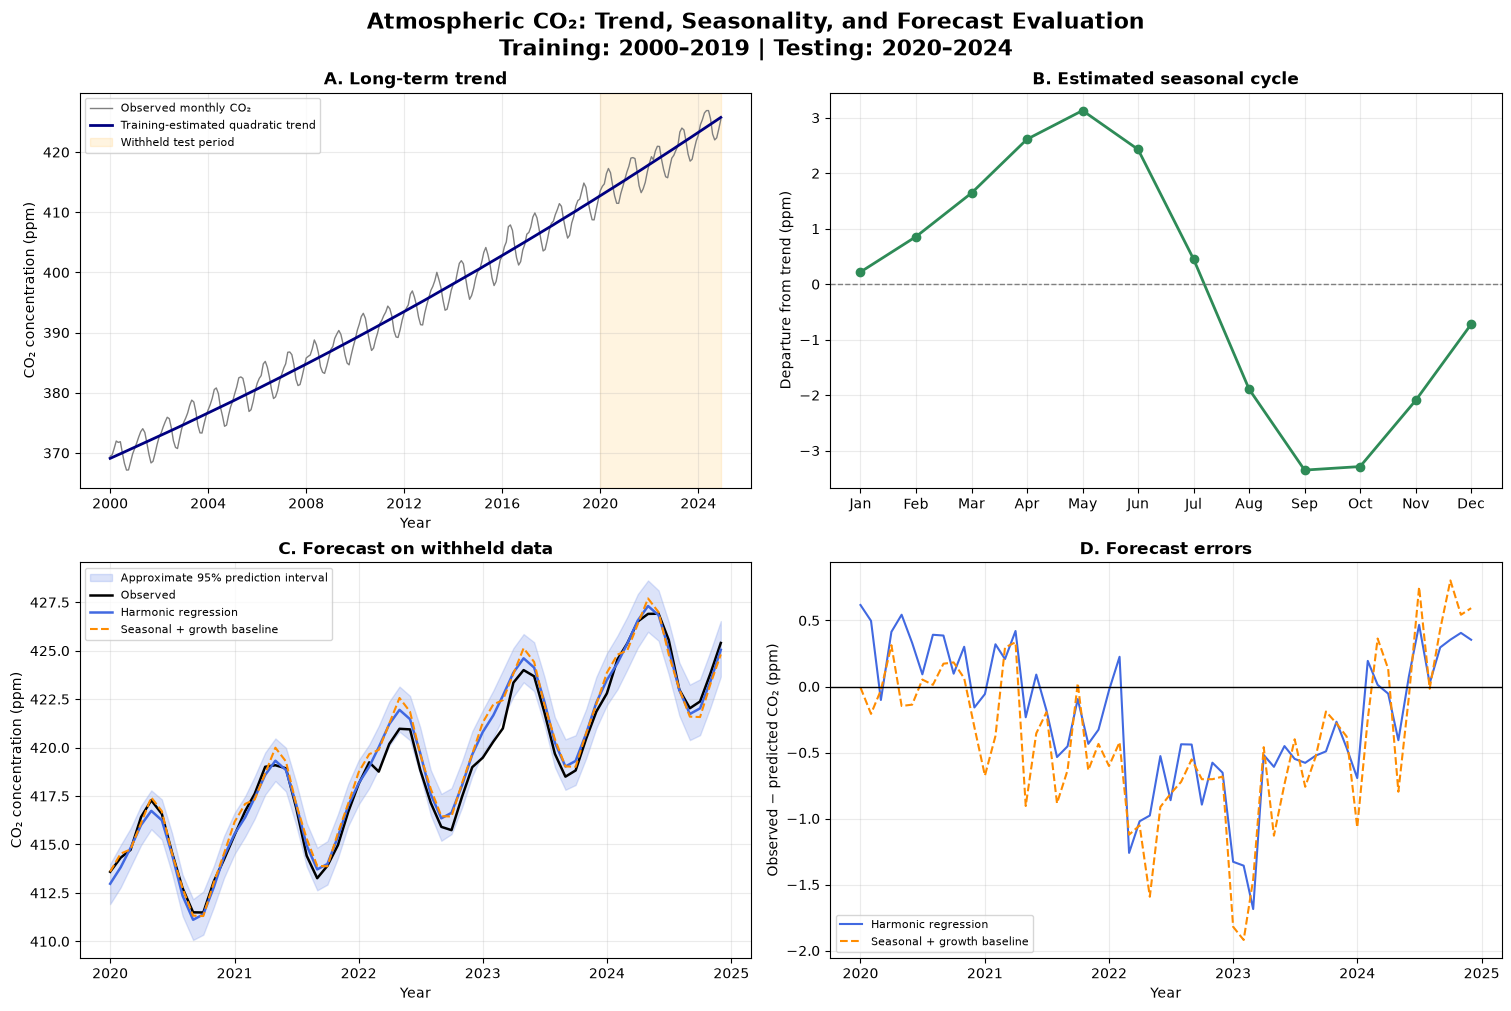

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

# Panel A: observations and training-estimated trend
ax = axes[0, 0]
ax.plot(co2.index, y, color="gray", linewidth=1, label="Observed monthly CO₂")

ax.plot(co2.index, trend, color="navy", linewidth=2, label="Training-estimated quadratic trend")

ax.axvspan(test_dates[0], test_dates[-1], color="orange", alpha=0.12, label="Withheld test period")

ax.set_title("A. Long-term trend", fontweight="bold")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(fontsize=8)

# Panel B: seasonal cycle
ax = axes[0, 1]
months = np.arange(1, 13)

ax.plot(months, seasonal[:12], marker="o", color="seagreen", linewidth=2)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(months)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("B. Estimated seasonal cycle", fontweight="bold")
ax.set_ylabel("Departure from trend (ppm)")

# Panel C: held-out forecast and uncertainty
ax = axes[1, 0]
ax.fill_between(test_dates, lower, upper, color="royalblue", alpha=0.18, label="Approximate 95% prediction interval")
ax.plot(test_dates, y_test, color="black", linewidth=1.8, label="Observed")
ax.plot(test_dates, prediction, color="royalblue", linewidth=1.8, label="Harmonic regression")
ax.plot(test_dates, baseline, color="darkorange", linestyle="--", linewidth=1.5, label="Seasonal + growth baseline")
ax.set_title("C. Forecast on withheld data", fontweight="bold")
ax.set_ylabel("CO₂ concentration (ppm)")
ax.legend(fontsize=8)

# Panel D: forecast errors
ax = axes[1, 1]

ax.plot(test_dates, y_test - prediction, color="royalblue", linewidth=1.5, label="Harmonic regression")
ax.plot(test_dates, y_test - baseline, color="darkorange", linestyle="--", linewidth=1.5, label="Seasonal + growth baseline")
ax.axhline(0, color="black", linewidth=1)
ax.set_title("D. Forecast errors", fontweight="bold")
ax.set_ylabel("Observed − predicted CO₂ (ppm)")
ax.legend(fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.25)
for ax in [axes[0, 0], axes[1, 0], axes[1, 1]]:
    ax.set_xlabel("Year")
fig.suptitle("Atmospheric CO₂: Trend, Seasonality, and Forecast Evaluation\n" "Training: 2000–2019 | Testing: 2020–2024", fontsize=16, fontweight="bold")

plt.show()

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


Using ChatGPT for this exercise helped me work with methods that would have been difficult to implement independently. However, its usefulness depends on whether I understand the code, verify the results, and clearly acknowledge its contribution.

- Wiley requires disclosure when AI contributes to coding or data analysis. **In this exercise, ChatGPT helped develop the regression model, bootstrap procedure, plots, and written explanation**, so I should acknowledge that assistance and remain responsible for the final work.

- AI supports my learning when I use it to understand unfamiliar methods. **For example, the sine and cosine terms represent the seasonal CO₂ cycle.** Simply copying those terms without understanding their purpose would limit the educational value.

- AI-generated code needs methodological checks even when it runs successfully. **Training on 2000–2019 and testing on 2020–2024 keeps future observations out of model fitting.** Comparing the forecast with a seasonal-growth baseline also checks whether the more complex model improves predictions.

- Uncertainty estimates should not be treated as guarantees. **The 12-month bootstrap blocks preserve some temporal dependence**, but the prediction intervals assume that future residual behavior resembles the training period. They cannot capture every possible change in the carbon cycle.

- AI assistance becomes unethical when it involves fabricated results, invented references, or concealed contributions. **The bootstrap simulations must be identified as simulated values, not additional NOAA observations.** Wiley also emphasizes protecting confidential information and intellectual property.

- AI infrastructure requires electricity and water for cooling, so unnecessary use has environmental costs. **I can reuse working code and avoid repeatedly requesting complete rewrites.** The 1,000 bootstrap repetitions run in Python rather than requiring 1,000 ChatGPT requests.

- In my final project, I could use AI to explain methods and debug code while checking its suggestions against original sources. **For example, AI could help write a basin-averaging function, but I would verify the basin boundaries, units, and area weighting** before interpreting the results.

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

#### Selecting and organizing data

| Command or technique | What it does | Simple example |
|:---|:---|:---|
| `.isin([...])` | Checks whether values belong to a list. | `.isin(["MID", "FWD"])` selects midfielders and forwards. |
| `&` | Requires both conditions to be true. | Select forwards **and** players with at least 450 minutes. |
| `.dropna(subset=[...])` | Removes rows missing values in specified columns. | Remove players whose goals or minutes are missing. |
| `.copy()` | Creates a separate copy for further calculations. | Calculate new statistics without changing the original selection's source. |
| `.sort_values()` | Sorts rows by one or more columns. | Sort by contribution rate, then use total contributions to break ties. |
| `.nlargest(3, "goals")` | Selects the three largest values in a column. | Find the three highest goalscorers. |
| `.head(5)` | Returns the first five rows. | Preview a dataset or select five players after sorting. |

#### Working with dates

| Command | Meaning | Example |
|:---|:---|:---|
| `pd.to_datetime()` | Converts values into dates. | Year 2020, month 3, day 1 becomes **2020-03-01**. |
| `.set_index("date")` | Uses dates as row labels. | Observations can then be selected by date. |
| `.sort_index()` | Sorts the index. | Arrange monthly observations from earliest to latest. |
| `.asfreq("MS")` | Uses a month-start frequency. | January 1, February 1, March 1, etc. |
| `.where(condition)` | Keeps values satisfying a condition and masks the others. | Applying a positive-value condition to `[400, -99, 402]` gives `[400, NaN, 402]`. |

**Reminder:** `.asfreq("MS")` does not calculate monthly averages or fill missing values. An absent month becomes `NaN`.

#### Understanding array slicing

Python indexing starts at **0**, and the stopping position of a slice is excluded.

For the array `[10, 20, 30, 40, 50]`:

| Expression | Result | Meaning |
|:---|:---|:---|
| `a[:3]` | `[10, 20, 30]` | First three values |
| `a[3:]` | `[40, 50]` | Values from index 3 onward |
| `a[-2:]` | `[40, 50]` | Last two values |
| `a[1:4]` | `[20, 30, 40]` | Indices 1, 2, and 3 |

For a two-dimensional array, `X[:, :3]` selects **all rows and the first three columns**.

#### Building numerical arrays

| Command | Purpose | Example |
|:---|:---|:---|
| `np.arange(4)` | Generates sequential values. | `[0, 1, 2, 3]` |
| `np.ones(3)` | Creates an array of ones. | `[1, 1, 1]` |
| `np.column_stack()` | Places arrays beside each other as columns. | `[1, 1]` and `[2, 3]` become rows `[1, 2]` and `[1, 3]`. |
| `np.concatenate()` | Joins arrays end to end. | `[1, 2]` and `[3, 4]` become `[1, 2, 3, 4]`. |
| `np.tile()` | Repeats an array. | Repeating `[1, 2]` three times gives `[1, 2, 1, 2, 1, 2]`. |
| `np.ceil()` | Rounds upward. | `2.3` becomes `3.0`. |
| `//` | Performs floor division. | `14 // 12` gives `1`. |


#### Plotting reminders

| Command or option | Purpose | Example |
|:---|:---|:---|
| `plt.subplots(2, 2)` | Creates four panels. | Compare trend, seasonality, forecasts, and errors. |
| `axes[1, 0]` | Selects the bottom-left panel. | Row 1, column 0 |
| `axes.flat` | Iterates through all panels. | Apply gridlines to every subplot. |
| `barh(..., left=...)` | Creates horizontally stacked bars. | Start assists where the goals bar ends. |
| `scatter(..., s=...)` | Controls marker area. | Larger bubbles represent more minutes played. |
| `fill_between()` | Shades between two curves. | Show lower and upper prediction bounds. |
| `axvspan()` | Shades an x-axis interval. | Highlight the testing period. |
| `axhline(0)` | Draws a horizontal line at zero. | Separate positive and negative errors. |
| `alpha=0.3` | Sets transparency. | 0 is invisible; 1 is fully opaque. |

**Boxplot reminder:** The box spans Q1 to Q3, and the internal line shows the median. Default whiskers reach the most extreme observations within 1.5 × IQR of the box. Points beyond them are potential outliers, not automatically errors.

#### Formatting output

- `.round(3)` returns values rounded to three decimal places.
- `display()` presents a formatted table in Jupyter.
- An f-string inserts values into text.
- `:.2f` displays two decimal places.

**Example:** Formatting `1.2367` with `:.2f` displays **1.24**, without changing the original stored value.